# Image Classification: MDA vs U937

Binary classification of 728 microscopy images using convolutional
neural networks (CNNs) and transfer learning.


- **MDA (MDA-MB series):** Human breast cancer cells, typically adherent.
- **U937:** Human monocytic leukemia cells, typically growing in suspension.

They differ in their origin, shape, size, and internal structure, which can affect how they scatter light and produce holographic diffraction patterns.

These differences can be used to investigate **label-free cell classification using machine learning**.

**Objectives**
- Explore image characteristics and class distribution.
- Train a baseline CNN.
- Compare pretrained MobileNetV2 models and optimizers.
- Evaluate classification performance on independent test data.


In [1]:
# Standard libraries
from pathlib import Path
from collections import Counter

# Data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

# Dataset downloading
import opendatasets as od

# Machine learning and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Statistical analysis
from statsmodels.stats.proportion import proportion_confint

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch: {torch.__version__}")
print(f"Device: {device}")

PyTorch: 2.15.0+cu132
Device: cuda


In [3]:
# make sure to download dataset from Kaggle and put into the same directory 

DATA_DIR = Path("classcrossfin")

if not DATA_DIR.exists():
    od.download(
        "https://www.kaggle.com/datasets/aliaslandemir/classcrossfin"
    )

print(f"Dataset: {DATA_DIR.resolve()}")

# Kaggle username: aliaslandemir
# Kaggle Key: 6f8335ed8437205e08381585952f57ed

Dataset: /home/ali/projects/general_analysis/classcrossfin


## 1.1 Dataset structure

Images are stored as individual JPG files in two class directories.

- `mda/`: MDA images (class 0)
- `u937/`: U937 images (class 1)

The original images are preserved without modification.

In [ ]:
# 2 class problem, mda is cancer cell and u937 is an alternative.


# Dataset directory
DATA_DIR = Path.cwd() / "classcrossfin"

# Load dataset
dataset = datasets.ImageFolder(root=DATA_DIR)

print("Dataset path:", DATA_DIR.resolve())
print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Mapping:", dataset.class_to_idx)

# Count images per class
counts = Counter(dataset.targets)

for label, count in sorted(counts.items()):
    print(f"{dataset.classes[label]}: {count} images")

Dataset path: /home/ali/projects/general_analysis/classcrossfin
Total images: 1456
Classes: ['mda', 'u937']
Mapping: {'mda': 0, 'u937': 1}
mda: 728 images
u937: 728 images


## 1.3 Image characteristics

Inspect image dimensions, pixel intensity, and representative samples.

This helps identify differences in illumination, noise, and morphology.

In [5]:
# Look for image properties quickly

properties = []

for path, label in dataset.samples:
    img = np.asarray(dataset.loader(path).convert("L"))

    properties.append({
        "class": dataset.classes[label],
        "width": img.shape[1],
        "height": img.shape[0],
        "mean": img.mean(),
        "std": img.std()
    })

df = pd.DataFrame(properties)

display(df.groupby("class")[["mean", "std"]].agg(["mean", "std"]))
print(df[["width", "height"]].value_counts())

mean                   std          
             mean        std       mean       std
class                                            
mda    102.545015   5.165891  15.438324  2.670582
u937   108.456055  10.969931  11.672098  2.559782

width  height
200    200       1456
Name: count, dtype: int64


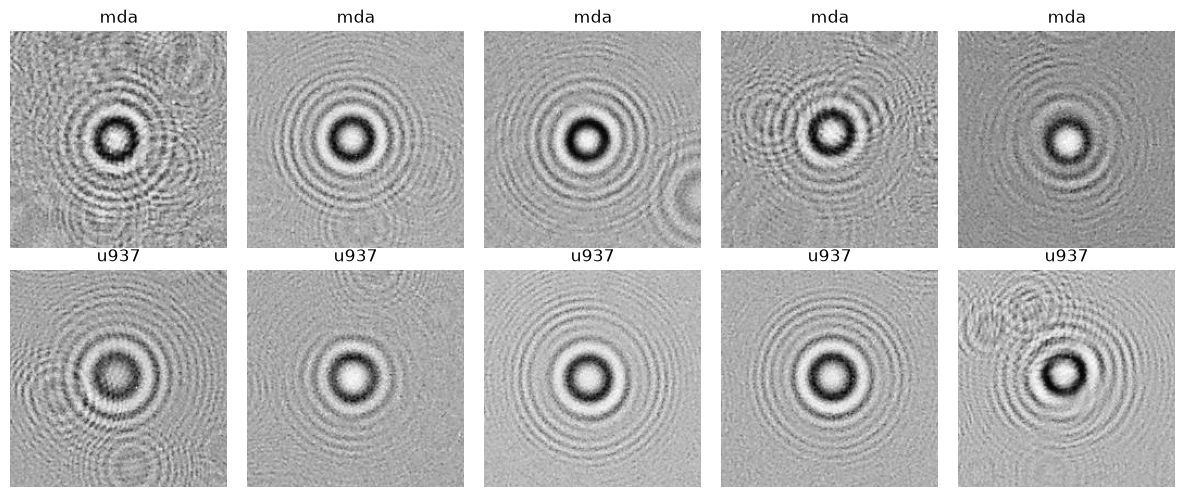

In [6]:
# Visualize some samples


fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for row, class_name in enumerate(dataset.classes):

    indices = np.where(np.array(dataset.targets) == row)[0]
    selected = np.random.choice(indices, 5, replace=False)

    for ax, idx in zip(axes[row], selected):
        img, label = dataset[idx]

        ax.imshow(img.convert("L"), cmap="gray")
        ax.set_title(class_name)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 2.1 Train / Validation / Test split

The dataset is divided into:

- Training: 70%
- Validation: 15%
- Testing: 15%

Stratified splitting maintains class proportions.

The test set is reserved for final evaluation.

In [7]:
# Change test size values to adjust division of datasets

labels = np.array(dataset.targets)
indices = np.arange(len(dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=labels[temp_idx],
    random_state=SEED
)

split_stats = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Count": [len(train_idx), len(val_idx), len(test_idx)]
})

display(split_stats)

,Split,Count
0,Train,1019
1,Validation,218
2,Test,219


In [8]:
# You can also add different transformations like rotation, flipping, etc. to augment the training dataset.


train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), # Convert to grayscale
    transforms.ToTensor() # make it tensor
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

In [9]:
# Subset, batch and shuffle the datasets

train_data = Subset(
    datasets.ImageFolder(DATA_DIR, transform=train_transform),
    train_idx
)

val_data = Subset(
    datasets.ImageFolder(DATA_DIR, transform=eval_transform),
    val_idx
)

test_data = Subset(
    datasets.ImageFolder(DATA_DIR, transform=eval_transform),
    test_idx
)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

images, targets = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", targets.shape)

Images: torch.Size([32, 1, 200, 200])
Labels: torch.Size([32])


## 3.1 Baseline CNN architecture

A compact convolutional network is trained from scratch.

Architecture:
1. Three convolutional layers (16, 32, 64 filters).
2. ReLU activation and max pooling.
3. Global average pooling.
4. Fully connected classification layer.

Cross-entropy loss is used for binary classification with two logits.

In [10]:
# This NN has 3 convolutional layers followed by 2 fully connected layers. It uses ReLU activation and dropout for regularization. The final layer has 2 output units for binary classification.


class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = SimpleCNN().to(device)

n_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {n_params:,}")

Trainable parameters: 25,442


## 4.1 Model training

The training loop performs:

1. Forward propagation.
2. Cross-entropy loss calculation.
3. Backpropagation.
4. Optimizer update.
5. Validation after each epoch.

The model with the lowest validation loss is retained.

In [11]:
# 20 epochs, optimizer is Adam, loss function is CrossEntropyLoss.


def train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        epochs=20,
        freeze_bn=False
    ):

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_loss = float("inf")
    best_state = None

    for epoch in range(epochs):

        # Training
        model.train()

        if freeze_bn:
            freeze_batchnorm(model)
        train_loss, train_correct, train_total = 0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(y)
            train_correct += (outputs.argmax(1) == y).sum().item()
            train_total += len(y)

        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)

                outputs = model(x)
                loss = criterion(outputs, y)

                val_loss += loss.item() * len(y)
                val_correct += (outputs.argmax(1) == y).sum().item()
                val_total += len(y)

        train_loss /= train_total
        val_loss /= val_total

        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train: {train_acc:.3f} | "
            f"Val: {val_acc:.3f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

## 5.1 Baseline training

The CNN is trained using Adam with a learning rate of 0.001.

Training and validation losses are monitored to detect overfitting.

In [12]:
# train the model

torch.manual_seed(SEED)

cnn = SimpleCNN().to(device)

optimizer = torch.optim.Adam(
    cnn.parameters(),
    lr=1e-3
)

cnn, cnn_history = train_model(
    cnn,
    train_loader,
    val_loader,
    optimizer,
    epochs=20
)

Epoch 01 | Train: 0.496 | Val: 0.500 | Val Loss: 0.6931
Epoch 02 | Train: 0.516 | Val: 0.468 | Val Loss: 0.6916
Epoch 03 | Train: 0.575 | Val: 0.716 | Val Loss: 0.6747
Epoch 04 | Train: 0.743 | Val: 0.711 | Val Loss: 0.6362
Epoch 05 | Train: 0.757 | Val: 0.739 | Val Loss: 0.5996
Epoch 06 | Train: 0.727 | Val: 0.697 | Val Loss: 0.6089
Epoch 07 | Train: 0.783 | Val: 0.711 | Val Loss: 0.5811
Epoch 08 | Train: 0.783 | Val: 0.702 | Val Loss: 0.5919
Epoch 09 | Train: 0.785 | Val: 0.716 | Val Loss: 0.5538
Epoch 10 | Train: 0.782 | Val: 0.716 | Val Loss: 0.5431
Epoch 11 | Train: 0.794 | Val: 0.725 | Val Loss: 0.5190
Epoch 12 | Train: 0.800 | Val: 0.775 | Val Loss: 0.4753
Epoch 13 | Train: 0.787 | Val: 0.752 | Val Loss: 0.4611
Epoch 14 | Train: 0.801 | Val: 0.789 | Val Loss: 0.4489
Epoch 15 | Train: 0.810 | Val: 0.784 | Val Loss: 0.4576
Epoch 16 | Train: 0.804 | Val: 0.794 | Val Loss: 0.4941
Epoch 17 | Train: 0.815 | Val: 0.794 | Val Loss: 0.4874
Epoch 18 | Train: 0.810 | Val: 0.812 | Val Loss:

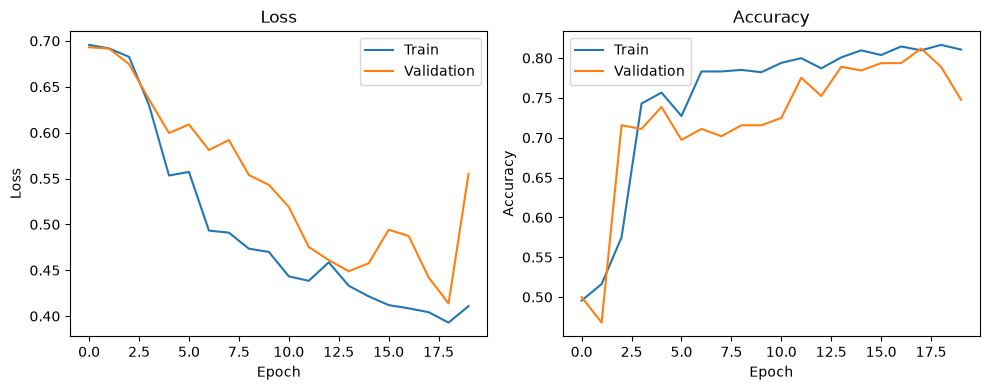

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(cnn_history["train_loss"], label="Train")
axes[0].plot(cnn_history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()

axes[1].plot(cnn_history["train_acc"], label="Train")
axes[1].plot(cnn_history["val_acc"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6.1 Pretrained MobileNetV2

MobileNetV2 is initialized with ImageNet-pretrained weights.

First, the feature extractor is frozen and only the final
classification layer is trained.

Since MobileNetV2 expects three-channel images, grayscale images
are converted to three channels and normalized using ImageNet statistics.

In [ ]:
# MobileNetV2 preprocessing and size match + batch
weights = models.MobileNet_V2_Weights.DEFAULT

mobilenet_train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

mobilenet_eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Datasets
mobilenet_train = Subset(
    datasets.ImageFolder(DATA_DIR, transform=mobilenet_train_transform),
    train_idx
)

mobilenet_val = Subset(
    datasets.ImageFolder(DATA_DIR, transform=mobilenet_eval_transform),
    val_idx
)

mobilenet_test = Subset(
    datasets.ImageFolder(DATA_DIR, transform=mobilenet_eval_transform),
    test_idx
)

# DataLoaders
mobilenet_train_loader = DataLoader(
    mobilenet_train, batch_size=32, shuffle=True
)

mobilenet_val_loader = DataLoader(
    mobilenet_val, batch_size=32, shuffle=False
)

mobilenet_test_loader = DataLoader(
    mobilenet_test, batch_size=32, shuffle=False
)

In [15]:
# Model linear layer replacement and freezing pretrained backbone.

def freeze_batchnorm(model):
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


def create_mobilenet():
    model = models.mobilenet_v2(weights=weights)

    # Freeze pretrained backbone
    for param in model.parameters():
        param.requires_grad = False

    # Replace classification layer
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features, 2
    )

    return model.to(device)


mobilenet = create_mobilenet()

print("Trainable parameters:", sum(
    p.numel() for p in mobilenet.parameters()
    if p.requires_grad
))

Trainable parameters: 2562


In [16]:
# Optimizer for MobileNetV2, using AdamW with a learning rate of 1e-3.

optimizer = torch.optim.AdamW(
    mobilenet.classifier.parameters(),
    lr=1e-3
)

mobilenet, mobilenet_history = train_model(
    mobilenet,
    mobilenet_train_loader,
    mobilenet_val_loader,
    optimizer,
    epochs=15,
    freeze_bn=True
)

Epoch 01 | Train: 0.657 | Val: 0.679 | Val Loss: 0.5959
Epoch 02 | Train: 0.739 | Val: 0.693 | Val Loss: 0.5455
Epoch 03 | Train: 0.767 | Val: 0.670 | Val Loss: 0.5149
Epoch 04 | Train: 0.779 | Val: 0.683 | Val Loss: 0.5013
Epoch 05 | Train: 0.791 | Val: 0.743 | Val Loss: 0.4745
Epoch 06 | Train: 0.813 | Val: 0.739 | Val Loss: 0.4610
Epoch 07 | Train: 0.812 | Val: 0.702 | Val Loss: 0.4593
Epoch 08 | Train: 0.820 | Val: 0.817 | Val Loss: 0.4479
Epoch 09 | Train: 0.824 | Val: 0.826 | Val Loss: 0.4426
Epoch 10 | Train: 0.831 | Val: 0.830 | Val Loss: 0.4323
Epoch 11 | Train: 0.845 | Val: 0.817 | Val Loss: 0.4317
Epoch 12 | Train: 0.851 | Val: 0.817 | Val Loss: 0.4295
Epoch 13 | Train: 0.834 | Val: 0.835 | Val Loss: 0.4164
Epoch 14 | Train: 0.856 | Val: 0.821 | Val Loss: 0.4090
Epoch 15 | Train: 0.851 | Val: 0.803 | Val Loss: 0.4058


## 7.1 Optimizer comparison

Compare three optimization algorithms:

- Adam: Adaptive learning rates.
- AdamW: Adam with decoupled weight decay.
- SGD: Momentum-based gradient descent.

Each experiment starts from identical CNN weights.

Validation performance is used for model comparison.

In [17]:
# Look for different optimizers and their effects on training.


optimizers = {
    "Adam": lambda params: torch.optim.Adam(params, lr=1e-3),
    "AdamW": lambda params: torch.optim.AdamW(
        params, lr=1e-3, weight_decay=1e-2
    ),
    "SGD": lambda params: torch.optim.SGD(
        params, lr=1e-2, momentum=0.9
    )
}

results = {}
trained_models = {}

torch.manual_seed(SEED)
initial_model = SimpleCNN()
initial_weights = {
    k: v.clone()
    for k, v in initial_model.state_dict().items()
}

for name, make_optimizer in optimizers.items():

    print(f"\nTraining with {name}")

    torch.manual_seed(SEED)

    model = SimpleCNN().to(device)
    model.load_state_dict(initial_weights)

    optimizer = make_optimizer(model.parameters())

    model, history = train_model(
        model, train_loader, val_loader,
        optimizer, epochs=20
    )

    results[name] = history
    trained_models[name] = model


Training with Adam
Epoch 01 | Train: 0.496 | Val: 0.500 | Val Loss: 0.6931
Epoch 02 | Train: 0.515 | Val: 0.463 | Val Loss: 0.6911
Epoch 03 | Train: 0.577 | Val: 0.711 | Val Loss: 0.6765
Epoch 04 | Train: 0.733 | Val: 0.711 | Val Loss: 0.6457
Epoch 05 | Train: 0.754 | Val: 0.734 | Val Loss: 0.5970
Epoch 06 | Train: 0.723 | Val: 0.716 | Val Loss: 0.6293
Epoch 07 | Train: 0.782 | Val: 0.720 | Val Loss: 0.5663
Epoch 08 | Train: 0.779 | Val: 0.711 | Val Loss: 0.5895
Epoch 09 | Train: 0.793 | Val: 0.716 | Val Loss: 0.5410
Epoch 10 | Train: 0.784 | Val: 0.725 | Val Loss: 0.5136
Epoch 11 | Train: 0.794 | Val: 0.752 | Val Loss: 0.5080
Epoch 12 | Train: 0.804 | Val: 0.784 | Val Loss: 0.4719
Epoch 13 | Train: 0.791 | Val: 0.780 | Val Loss: 0.4660
Epoch 14 | Train: 0.805 | Val: 0.766 | Val Loss: 0.4470
Epoch 15 | Train: 0.807 | Val: 0.794 | Val Loss: 0.4642
Epoch 16 | Train: 0.808 | Val: 0.812 | Val Loss: 0.4785
Epoch 17 | Train: 0.817 | Val: 0.803 | Val Loss: 0.4823
Epoch 18 | Train: 0.816 | Va

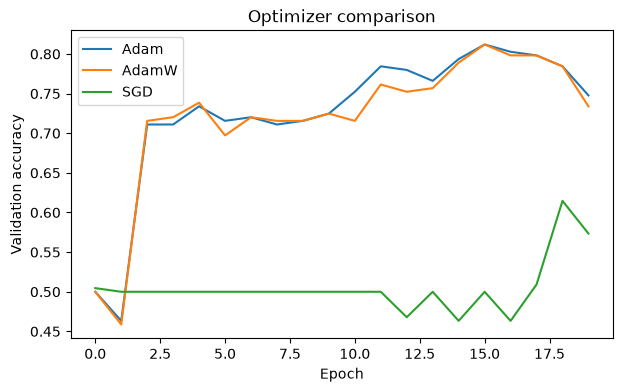

,Best val accuracy,Minimum val loss
Adam,0.811927,0.423304
AdamW,0.811927,0.458668
SGD,0.614679,0.692762


In [18]:
plt.figure(figsize=(7, 4))

for name, history in results.items():
    plt.plot(history["val_acc"], label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Optimizer comparison")
plt.legend()
plt.show()

comparison = pd.DataFrame({
    name: {
        "Best val accuracy": history["val_acc"].max(),
        "Minimum val loss": history["val_loss"].min()
    }
    for name, history in results.items()
}).T

display(comparison)

## 8.1 Fine-tuning

Unfreeze the final residual block (layer4) of MobileNetV2.

Use a smaller learning rate for pretrained layers to reduce
the risk of destroying previously learned features.

Compare the fine-tuned model with the frozen-feature baseline.

In [19]:
# Unfreeze the final feature blocks
for param in mobilenet.features[-3:].parameters():
    param.requires_grad = True

# Keep earlier layers frozen
optimizer = torch.optim.AdamW([
    {"params": mobilenet.features[-3:].parameters(), "lr": 1e-5},
    {"params": mobilenet.classifier.parameters(), "lr": 1e-4}
])



In [20]:
# Fine-tune MobileNetV2
mobilenet, finetune_history = train_model(
    mobilenet,
    mobilenet_train_loader,
    mobilenet_val_loader,
    optimizer,
    epochs=10,
    freeze_bn=True
)

Epoch 01 | Train: 0.851 | Val: 0.830 | Val Loss: 0.3677
Epoch 02 | Train: 0.864 | Val: 0.821 | Val Loss: 0.3577
Epoch 03 | Train: 0.863 | Val: 0.830 | Val Loss: 0.3768
Epoch 04 | Train: 0.875 | Val: 0.835 | Val Loss: 0.3627
Epoch 05 | Train: 0.889 | Val: 0.876 | Val Loss: 0.3265
Epoch 06 | Train: 0.885 | Val: 0.862 | Val Loss: 0.3262
Epoch 07 | Train: 0.894 | Val: 0.885 | Val Loss: 0.3240
Epoch 08 | Train: 0.912 | Val: 0.858 | Val Loss: 0.3231
Epoch 09 | Train: 0.921 | Val: 0.862 | Val Loss: 0.3267
Epoch 10 | Train: 0.905 | Val: 0.881 | Val Loss: 0.3180


## 9.1 Model evaluation

The selected model is evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

The test dataset is evaluated only after model selection.

In [21]:
# F1 or Recall or precision can be used to evaluate the model performance.


def evaluate_model(model, loader, class_names):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)

            outputs = model(x)
            predictions = outputs.argmax(dim=1)

            y_true.extend(y.numpy())
            y_pred.extend(predictions.cpu().numpy())

    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=class_names,
        cmap="Blues"
    )

    plt.title("Confusion matrix")
    plt.show()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1-macro": f1_score(y_true, y_pred, average="macro")
    }

              precision    recall  f1-score   support

         mda       0.94      0.89      0.92       110
        u937       0.90      0.94      0.92       109

    accuracy                           0.92       219
   macro avg       0.92      0.92      0.92       219
weighted avg       0.92      0.92      0.92       219



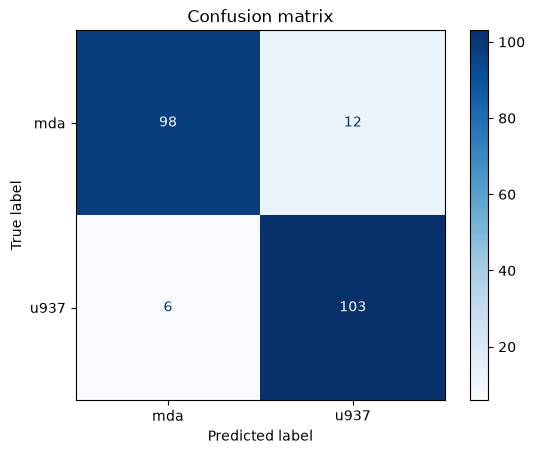

,Accuracy,F1-macro
0,0.917808,0.917765


In [22]:
final_model = mobilenet
final_loader = mobilenet_test_loader

test_metrics = evaluate_model(
    final_model,
    final_loader,
    dataset.classes
)

display(pd.DataFrame([test_metrics]))

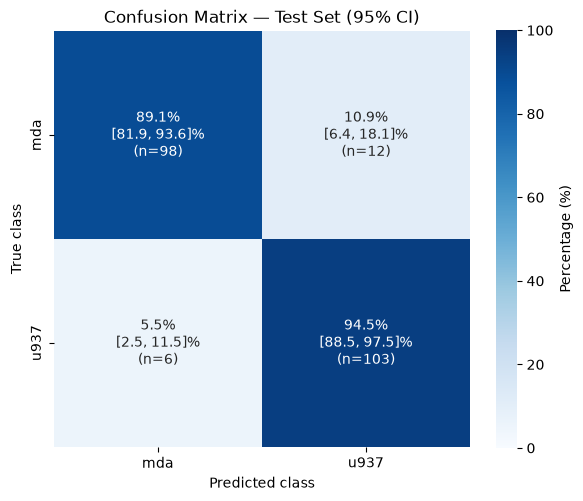

In [23]:

# Predictions
final_model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in final_loader:
        outputs = final_model(x.to(device))
        y_true.extend(y.numpy())
        y_pred.extend(outputs.argmax(1).cpu().numpy())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

# 95% confidence intervals (Wilson)
annotations = np.empty(cm.shape, dtype=object)

for i in range(cm.shape[0]):
    n = cm[i].sum()

    for j in range(cm.shape[1]):
        count = cm[i, j]

        low, high = proportion_confint(
            count, n, alpha=0.05, method="wilson"
        )

        p = cm_pct[i, j]


        annotations[i, j] = (
            f"{p:.1f}%\n"
            f"[{low*100:.1f}, {high*100:.1f}]%\n"
            f"(n={count})"
        )

# Plot
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_pct,
    annot=annotations,
    fmt="",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes,
    vmin=0,
    vmax=100,
    square=True,
    cbar_kws={"label": "Percentage (%)"}
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion Matrix — Test Set (95% CI)")
plt.tight_layout()
plt.show()

Grad-CAM (Gradient-weighted Class Activation Mapping) to visualize which regions of your holographic images influence the model's classification.

It produces a heatmap:
- Red/yellow: Regions contributing strongly to the predicted class.
- Blue: Regions with weaker contributions.


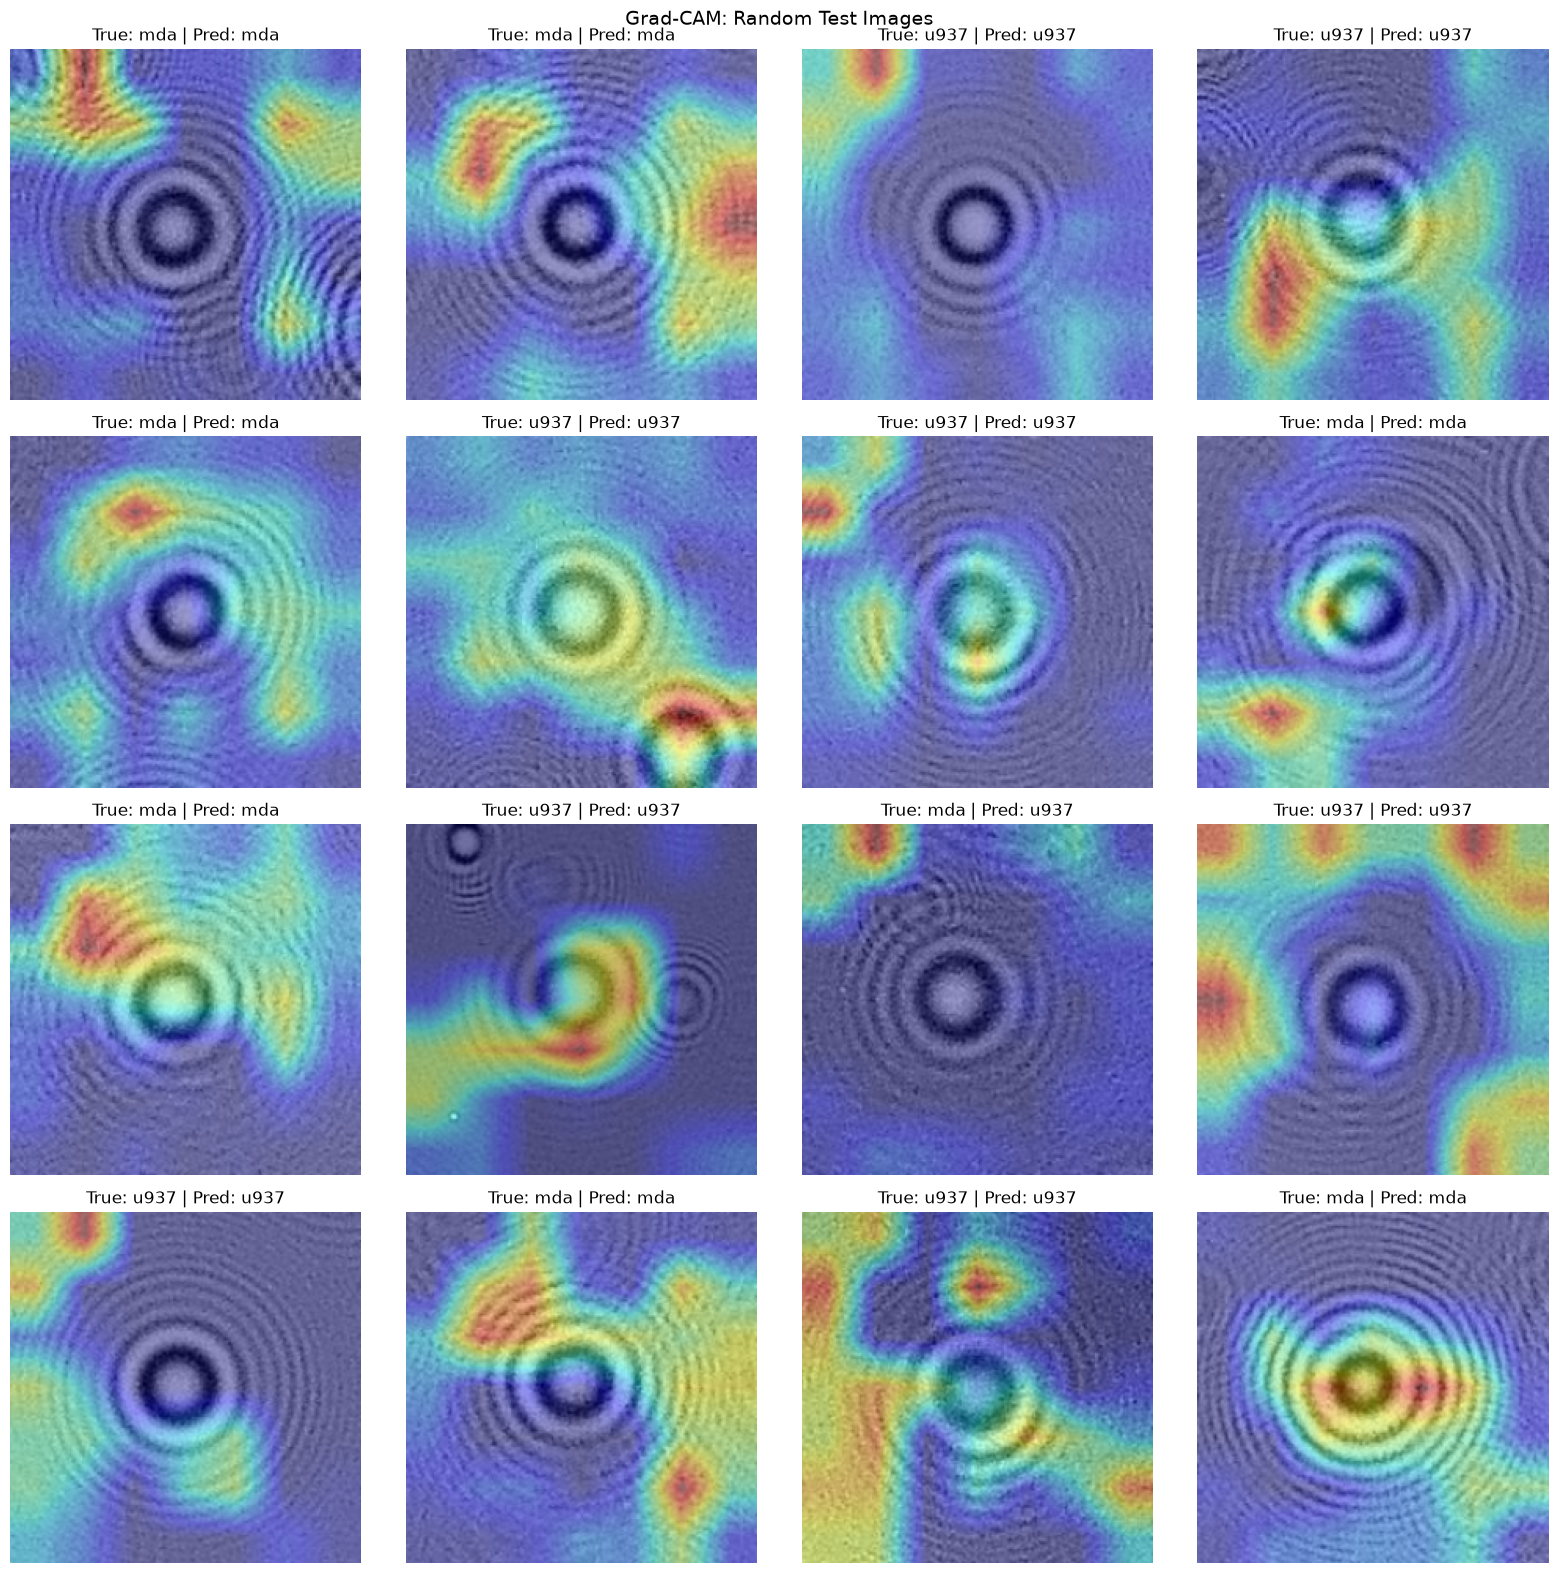

In [ ]:
# Grad-CAM: 16 random test images
final_model.eval()

activations = {}
gradients = {}

def save_features(module, inputs, output):
    activations["value"] = output.detach()
    output.register_hook(
        lambda grad: gradients.update(value=grad.detach())
    )

hook = final_model.features[-1].register_forward_hook(save_features)

# Random selection from test dataset
indices = torch.randperm(len(final_loader.dataset))[:16]

mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for ax, idx in zip(axes.flat, indices):
    image, label = final_loader.dataset[idx.item()]
    image = image.unsqueeze(0).to(device)

    # Forward and backward
    final_model.zero_grad()
    output = final_model(image)
    pred = output.argmax(dim=1).item()
    output[0, pred].backward()

    # Grad-CAM
    weights = gradients["value"].mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations["value"]).sum(dim=1)
    cam = torch.relu(cam)

    cam = torch.nn.functional.interpolate(
        cam.unsqueeze(1),
        size=image.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


    # Reverse ImageNet normalization
    original = image[0].detach().cpu() * std + mean

    # Convert reconstructed RGB channels to grayscale
    original = original.mean(dim=0).clamp(0, 1).numpy()

    # Overlay
    ax.imshow(original, cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)

    true_class = dataset.classes[label]
    pred_class = dataset.classes[pred]

    ax.set_title(f"True: {true_class} | Pred: {pred_class}")
    ax.axis("off")

hook.remove()

plt.suptitle("Grad-CAM: Random Test Images", fontsize=14)
plt.tight_layout()
plt.show()

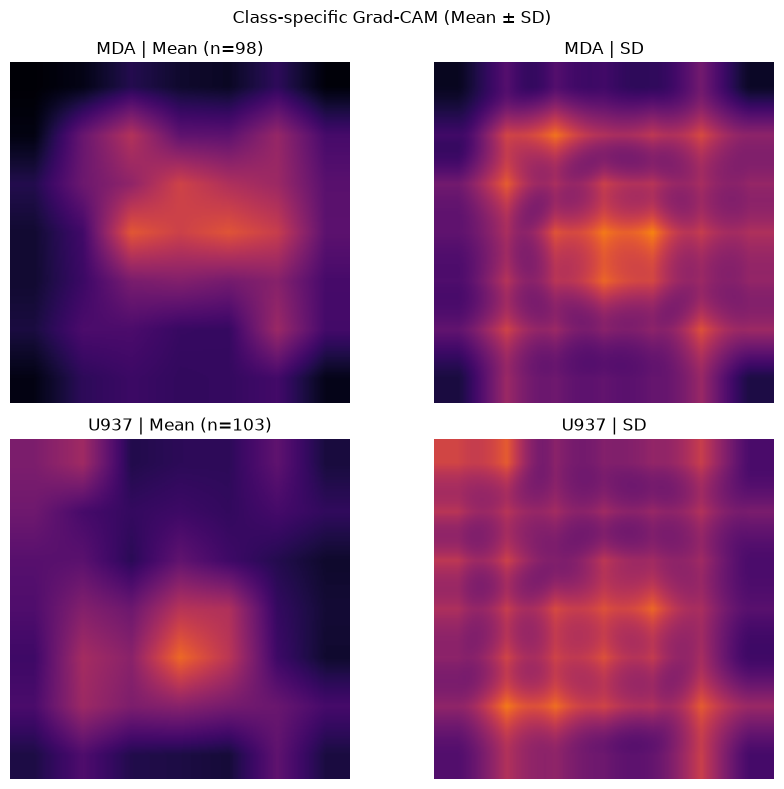

In [25]:
# Average Grad-CAM ± SD for each cell line
final_model.eval()

activations = {}
gradients = {}

def save_features(module, inputs, output):
    activations["value"] = output.detach()
    output.register_hook(
        lambda grad: gradients.update(value=grad.detach())
    )

hook = final_model.features[-1].register_forward_hook(save_features)

# Store heatmaps separately by true class
cams = {i: [] for i in range(len(dataset.classes))}

for images, labels in final_loader:
    for image, label in zip(images, labels):
        image = image.unsqueeze(0).to(device)
        label = label.item()

        final_model.zero_grad()
        output = final_model(image)
        pred = output.argmax(dim=1).item()

        # Only correctly classified images
        if pred != label:
            continue

        output[0, label].backward()

        weights = gradients["value"].mean(dim=(2, 3), keepdim=True)
        cam = (weights * activations["value"]).sum(dim=1)
        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam.unsqueeze(1),
            size=image.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].cpu().numpy()
        cam = cam / (cam.max() + 1e-8)

        cams[label].append(cam)

hook.remove()

# Visualization: rows = classes, columns = mean and SD
fig, axes = plt.subplots(2, 2, figsize=(9, 8))

for i, class_name in enumerate(dataset.classes):

    if not cams[i]:
        print(f"No correctly classified images for {class_name}")
        continue

    class_cams = np.stack(cams[i])

    mean_cam = class_cams.mean(axis=0)
    std_cam = class_cams.std(axis=0)

    axes[i, 0].imshow(mean_cam, cmap="inferno", vmin=0, vmax=1)
    axes[i, 0].set_title(
        f"{class_name.upper()} | Mean (n={len(class_cams)})"
    )

    axes[i, 1].imshow(std_cam, cmap="inferno", vmin=0, vmax=0.5)
    axes[i, 1].set_title(f"{class_name.upper()} | SD")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Class-specific Grad-CAM (Mean ± SD)")
plt.tight_layout()
plt.show()

## 10.1 Save model

Save the final model parameters and class mapping for future inference.

In [ ]:
# Save model with architecture and preprocessing metadata
torch.save({
    "architecture": "mobilenet_v2",
    "model_state_dict": final_model.state_dict(),
    "classes": dataset.classes,
    "num_classes": len(dataset.classes),

    "preprocessing": {
        "image_size": [224, 224],
        "grayscale_to_rgb": True,
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225]
    },

    "training": {
        "optimizer": "AdamW",
        "initial_epochs": 15,
        "finetuning_epochs": 10,
        "batch_size": 32,
        "seed": SEED
    },

    "test_metrics": test_metrics

}, "mobilenet_v2_classifier.pth")

print("Model saved successfully.")

Model saved successfully.
